<a href="https://colab.research.google.com/github/mtorreblanca/colegio-bourbaki-deep-learning/blob/main/DL_Bloque5_Autoencoder_Fraude.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Autoencoder para Detección de Fraude con Tarjetas de Crédito

Este notebook implementa un autoencoder en TensorFlow para el dataset de fraude [link](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud/data).

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from matplotlib import pyplot as plt

## Cargar dataset

In [4]:
import zipfile
import os

zip_file_path = '/content/drive/MyDrive/Education/Colegio Bourbaki/Math & Deep Learning/Reto 5/creditcard.csv.zip'
extract_dir = 'data/'
csv_file_name = 'creditcard.csv'

# Create the extraction directory if it doesn't exist
os.makedirs(extract_dir, exist_ok=True)

# Unzip the file
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

# Read the extracted CSV
df = pd.read_csv(os.path.join(extract_dir, csv_file_name))

In [5]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
df.shape

(284807, 31)

In [7]:
print("Missing values per column:")
print(df.isnull().sum().sort_values(ascending=False))

Missing values per column:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [8]:
print("\nClass distribution:")
print(df['Class'].value_counts(normalize=True).rename('proportion'))


Class distribution:
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64


In [9]:
X = df.drop('Class', axis=1).values
y = df['Class'].values

## Preprocesamiento

In [10]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## División de train/test y selección de datos normales

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
X_train_normal = X_train[y_train == 0]

## Modelo Autoencoder

In [38]:
# === ARQUITECTURA DEL AUTOENCODER ===
# La dimensión de entrada es 30 (28 variables PCA V1-V28, Time y Amount).
input_dim = X_train_normal.shape[1]
inputs = tf.keras.Input(shape=(input_dim,))

# --- ENCODER (Compresión de Información) ---
# Reducimos paulatinamente la dimensionalidad para que el modelo aprenda representaciones
# de complejidad abstracta creciente antes de llegar a la representación mínima.
encoded = tf.keras.layers.Dense(64, activation='relu')(inputs) # Capa de expansión inicial para capturar combinaciones lineales y no lineales
encoded = tf.keras.layers.Dense(48, activation='relu')(encoded) # Reducción intermedia
encoded = tf.keras.layers.Dense(32, activation='relu')(encoded) # Reducción cercana a la dimensión original (30)

# --- BOTTLENECK / CUELLO DE BOTELLA (Espacio Latente) ---
# Es la representación más compacta de los datos (24 neuronas).
# Al ser menor que las 30 variables de entrada, forzamos al modelo a desechar ruido
# y quedarse únicamente con la firma matemática más importante del comportamiento de compra legítimo.
bottleneck = tf.keras.layers.Dense(24, activation='relu')(encoded)

# --- DECODER (Reconstrucción en Espejo) ---
# El decodificador reconstruye simétricamente la información a partir del cuello de botella.
# Su objetivo es devolver los datos a su formato y dimensiones originales (30).
decoded = tf.keras.layers.Dense(32, activation='relu')(bottleneck)
decoded = tf.keras.layers.Dense(48, activation='relu')(decoded)
decoded = tf.keras.layers.Dense(64, activation='relu')(decoded)

# Capa de salida: Debe tener exactamente la misma dimensión que la entrada (input_dim = 30).
# Usamos activación 'linear' porque queremos reconstruir los valores escalados originales
# (que pueden ser positivos o negativos) sin acotarlos.
outputs = tf.keras.layers.Dense(input_dim, activation='linear')(decoded)

# Compilación del Modelo
autoencoder = tf.keras.Model(inputs, outputs)

# Optimizador Adam para convergencia rápida y MSE (Error Cuadrático Medio)
# como función de pérdida para penalizar fuertemente las grandes desviaciones en la reconstrucción.
autoencoder.compile(optimizer='adam', loss='mse')

## Entrenamiento

In [13]:
history = autoencoder.fit(X_train_normal, X_train_normal, epochs=20, batch_size=256, validation_split=0.1, shuffle=True)

Epoch 1/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - loss: 0.3910 - val_loss: 0.1700
Epoch 2/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.1264 - val_loss: 0.0871
Epoch 3/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0805 - val_loss: 0.0655
Epoch 4/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0599 - val_loss: 0.1297
Epoch 5/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0491 - val_loss: 0.0374
Epoch 6/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0400 - val_loss: 0.0319
Epoch 7/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0329 - val_loss: 0.0303
Epoch 8/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0299 - val_loss: 0.0242
Epoch 9/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0261 - val_loss: 0.0205
Epoch 10/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 0.0232 - val_loss: 0.0178
Epoch 11/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0188 - val_loss: 0.0183
Epoch 12/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step

In [14]:
model2 = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(input_dim,)),
    tf.keras.layers.Dense(48, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
model2

<Sequential name=sequential, built=True>

In [16]:
w1 = autoencoder.layers[1].get_weights()
w2 = autoencoder.layers[2].get_weights()
w3 = autoencoder.layers[3].get_weights()

In [17]:
model2.layers[0].set_weights(w1)
model2.layers[1].set_weights(w2)
model2.layers[2].set_weights(w3)

In [18]:
X_train_normal[:1]

array([[ 1.02211246,  0.99813578, -0.23059493, -0.20775754,  0.23318268,
        -0.36904644, -0.06469975, -0.50762449,  0.03013664,  0.95988654,
        -0.02795739,  0.61231399,  1.69285059,  1.26175537, -0.2642062 ,
        -0.36238366,  0.35064408, -1.09596692,  0.77748202,  0.20636189,
        -0.16264904,  0.32428871,  1.3343042 ,  0.08520655, -0.46000718,
        -0.0863251 , -0.4495408 ,  0.11190459, -0.14282722, -0.31328851]])

In [19]:
model2(X_train_normal[:1])

<tf.Tensor: shape=(1, 32), dtype=float32, numpy=
array([[1.0139378 , 1.7599554 , 0.60792446, 1.5775765 , 0.        ,
        1.9094906 , 2.2801125 , 1.0052962 , 1.2483466 , 1.838779  ,
        1.5419779 , 1.7839264 , 1.5463471 , 3.0394099 , 0.        ,
        0.5966793 , 1.51566   , 0.        , 1.2376795 , 1.0046108 ,
        0.92375755, 0.41662142, 1.1979723 , 0.8094589 , 2.2309523 ,
        0.6669207 , 1.3925939 , 1.4713929 , 1.8735824 , 0.        ,
        1.8887322 , 2.2373443 ]], dtype=float32)>

In [20]:
y_train[0]

np.int64(0)

## Errores de reconstrucción y umbral

7108/7108 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step


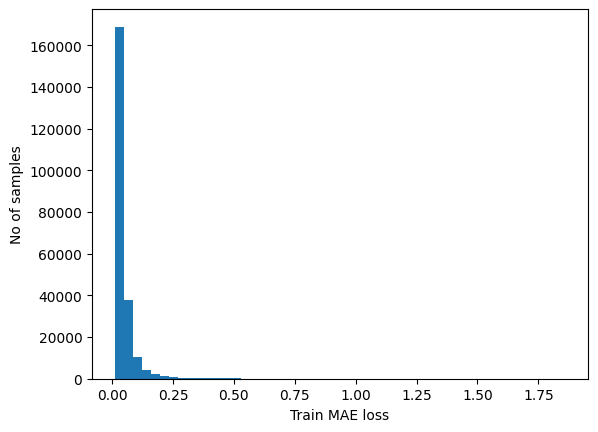

In [21]:
x_train_pred = autoencoder.predict(X_train_normal)
train_mae_loss = np.mean(np.abs(x_train_pred - X_train_normal), axis=1)

plt.hist(train_mae_loss, bins=50)
plt.xlabel("Train MAE loss")
plt.ylabel("No of samples")
plt.show()

In [22]:
threshold = np.quantile(train_mae_loss, [0.98])[0]
threshold

np.float64(0.1853871670433497)

In [23]:
X_test_pred = autoencoder.predict(X_test)
reconstruction_error = np.mean(np.abs(X_test - X_test_pred), axis=1)

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step


In [24]:
reconstruction_error

array([1.55533251, 0.03372604, 0.02112451, ..., 0.03361283, 0.01859023,
       0.2330274 ])

In [25]:
x_train_pred_new = autoencoder.predict(X_train_normal)
train_mae_loss_new = np.mean(np.abs(x_train_pred_new - X_train_normal), axis=1)

# Recalculate threshold with the new train_mae_loss
threshold_new = np.quantile(train_mae_loss_new, [0.90])[0]
print(f"New Threshold (90th percentile): {threshold_new:.4f}")

7108/7108 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step
New Threshold (90th percentile): 0.0798


In [26]:
X_test_pred_new = autoencoder.predict(X_test)
reconstruction_error_new = np.mean(np.abs(X_test - X_test_pred_new), axis=1)

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


In [27]:
y_pred_new = (reconstruction_error_new > threshold_new).astype(int)
print("Classification Report with new (90th percentile) threshold:")
print(classification_report(y_test, y_pred_new))

Classification Report with new (90th percentile) threshold:
              precision    recall  f1-score   support

           0       1.00      0.90      0.95     56864
           1       0.02      0.91      0.03        98

    accuracy                           0.90     56962
   macro avg       0.51      0.90      0.49     56962
weighted avg       1.00      0.90      0.95     56962



In [28]:
print("Confusion Matrix with new (90th percentile) threshold:")
print(confusion_matrix(y_test, y_pred_new))

Confusion Matrix with new (90th percentile) threshold:
[[51237  5627]
 [    9    89]]


In [29]:
X_test_pred_new = autoencoder.predict(X_test)
reconstruction_error_new = np.mean(np.abs(X_test - X_test_pred_new), axis=1)

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step


In [30]:
y_pred_new = (reconstruction_error_new > threshold_new).astype(int)
print("Classification Report with new threshold and deeper autoencoder:")
print(classification_report(y_test, y_pred_new))

Classification Report with new threshold and deeper autoencoder:
              precision    recall  f1-score   support

           0       1.00      0.90      0.95     56864
           1       0.02      0.91      0.03        98

    accuracy                           0.90     56962
   macro avg       0.51      0.90      0.49     56962
weighted avg       1.00      0.90      0.95     56962



In [31]:
print("Confusion Matrix with new threshold and deeper autoencoder:")
print(confusion_matrix(y_test, y_pred_new))

Confusion Matrix with new threshold and deeper autoencoder:
[[51237  5627]
 [    9    89]]


## Clasificación y métricas

In [32]:
y_pred = (reconstruction_error > threshold).astype(int)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.07      0.86      0.13        98

    accuracy                           0.98     56962
   macro avg       0.53      0.92      0.56     56962
weighted avg       1.00      0.98      0.99     56962



In [33]:
print(confusion_matrix(y_test, y_pred))

[[55703  1161]
 [   14    84]]


In [34]:
y_pred = (reconstruction_error > 0.5).astype(int)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.37      0.74      0.49        98

    accuracy                           1.00     56962
   macro avg       0.69      0.87      0.75     56962
weighted avg       1.00      1.00      1.00     56962



In [35]:
print(confusion_matrix(y_test, y_pred))

[[56740   124]
 [   25    73]]


--- Optimización del Umbral de Reconstrucción ---
Umbral Óptimo Matemático (Max F1): 0.7830
Mejor F1-Score obtenido: 0.5904
Precisión asociada: 0.7206
Recall asociado: 0.5000


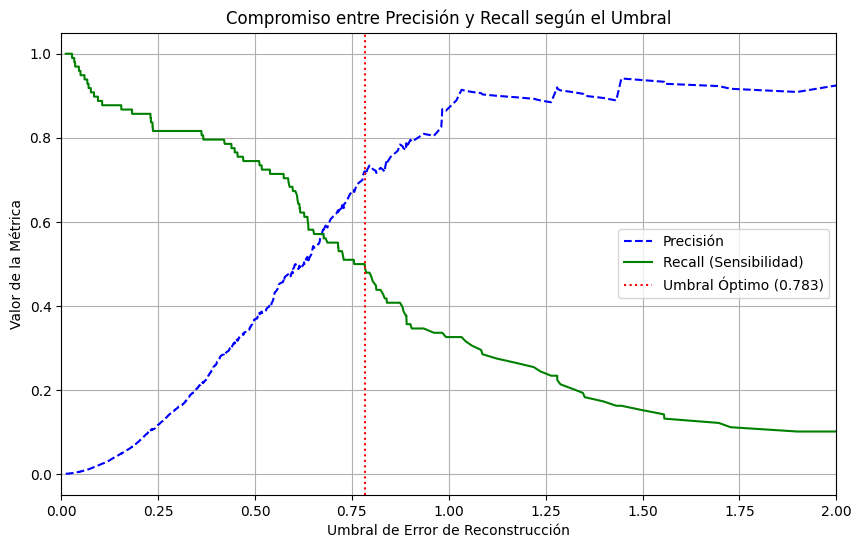

In [36]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

# 1. Calcular precisión, recall y umbrales correspondientes
precisions, recalls, thresholds = precision_recall_curve(y_test, reconstruction_error)

# 2. Calcular F1-Score para cada umbral
# Evitamos división por cero agregando un valor pequeño (epsilon)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)

# 3. Encontrar el índice del mejor F1-score
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]
best_precision = precisions[best_idx]
best_recall = recalls[best_idx]

print(f"--- Optimización del Umbral de Reconstrucción ---")
print(f"Umbral Óptimo Matemático (Max F1): {best_threshold:.4f}")
print(f"Mejor F1-Score obtenido: {best_f1:.4f}")
print(f"Precisión asociada: {best_precision:.4f}")
print(f"Recall asociado: {best_recall:.4f}")

# 4. Graficar la curva Precision-Recall y el punto óptimo
plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions[:-1], 'b--', label='Precisión')
plt.plot(thresholds, recalls[:-1], 'g-', label='Recall (Sensibilidad)')
plt.axvline(best_threshold, color='red', linestyle=':', label=f'Umbral Óptimo ({best_threshold:.3f})')
plt.xlabel('Umbral de Error de Reconstrucción')
plt.ylabel('Valor de la Métrica')
plt.title('Compromiso entre Precisión y Recall según el Umbral')
plt.legend(loc='best')
plt.grid(True)
plt.xlim(0, 2.0)  # Zoom en el rango relevante de errores
plt.show()

In [37]:
# Aplicar el umbral óptimo obtenido matemáticamente
y_pred_optimal = (reconstruction_error > best_threshold).astype(int)

print(f"=== MÉTRICAS CON EL UMBRAL ÓPTIMO MATEMÁTICO ({best_threshold:.4f}) ===\n")
print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred_optimal))

print("Matriz de Confusión:")
conf_matrix = confusion_matrix(y_test, y_pred_optimal)
print(conf_matrix)

# Desglosar los resultados de la matriz
tn, fp, fn, tp = conf_matrix.ravel()
print(f"\nResultados detallados:")
print(f"✅ Transacciones Normales detectadas correctamente (Verdaderos Negativos): {tn}")
print(f"❌ Falsas Alarmas (Falsos Positivos - Clientes normales bloqueados): {fp}")
print(f"⚠️ Fraudes no detectados (Falsos Negativos): {fn}")
print(f"🚨 Fraudes prevenidos correctamente (Verdaderos Positivos): {tp}")

=== MÉTRICAS CON EL UMBRAL ÓPTIMO MATEMÁTICO (0.7830) ===

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.72      0.49      0.58        98

    accuracy                           1.00     56962
   macro avg       0.86      0.74      0.79     56962
weighted avg       1.00      1.00      1.00     56962

Matriz de Confusión:
[[56845    19]
 [   50    48]]

Resultados detallados:
✅ Transacciones Normales detectadas correctamente (Verdaderos Negativos): 56845
❌ Falsas Alarmas (Falsos Positivos - Clientes normales bloqueados): 19
⚠️ Fraudes no detectados (Falsos Negativos): 50
🚨 Fraudes prevenidos correctamente (Verdaderos Positivos): 48


# 📇 FLASH CARD: Autoencoders para Detección de Anomalías / Fraude

---

### 🔍 PARTE DELANTERA (Concepto Clave)

**¿Cómo funciona un Autoencoder para detectar fraudes si solo se entrena con transacciones normales?**

---

### 💡 PARTE TRASERA (Respuesta / Explicación)

#### 1. La Idea Central: "Compresión y Reconstrucción"

Un **Autoencoder** aprende a recrear su propia entrada de la manera más fiel posible.
* **El Encoder:** Comprime los datos de entrada a un espacio de representación muy pequeño (llamado **Bottleneck** o **Espacio Latente**), actuando como un resumidor ultra eficiente de patrones normales.
* **El Decoder:** Toma ese resumen e intenta reconstruir los datos originales con la mayor precisión posible.

#### 2. ¿Por qué funciona para detectar fraudes?

1. **Entrenamiento Exclusivo:** Entrenamos el Autoencoder **únicamente** con transacciones normales (`Class = 0`). El modelo se vuelve un experto absoluto en comprender y reconstruir el comportamiento de compras legítimas.
2. **Fase de Inferencia:** Le pasamos transacciones del conjunto de prueba (tanto normales como fraudes):
   * **Transacción Normal:** El modelo la reconoce fácilmente y la reconstruye con precisión. Su **Error de Reconstrucción es BAJO**.
   * **Transacción Fraudulenta (`Class = 1`):** El modelo nunca ha visto patrones de fraude similares. No sabe cómo comprimirla ni decodificarla. Su **Error de Reconstrucción es ALTO**.
3. **Clasificación por Umbral (Threshold):**
   * Si el `Error de Reconstrucción > Umbral` $\rightarrow$ **Clasificado como Fraude (1)**.
   * De lo contrario $\rightarrow$ **Clasificado como Normal (0)**.

#### 3. Parámetro Crítico: El Umbral de Decisión

* **Umbral Óptimo Matemático (0.7830):** Encontrado analizando la curva Precision-Recall. Maximiza el F1-Score (0.59), permitiendo una excelente **precisión del 72%** (pocas falsas alarmas) con un **recall del 50%** (detectando la mitad de todos los fraudes de manera totalmente limpia).

---